# 1D MF example: high-frequency localized correction

Companion to `ExampleMF1D.ipynb` (smooth Gaussian correction). Here the HF–LF residual is a **localized high-frequency bump**:

$$u_{LF}(x,\mu)=\sin(\mu\pi x),\qquad u_{HF}(x,\mu)=u_{LF}(x,\mu)+\tfrac12\sin(6\pi\mu)\,\sin(30\pi x)\,e^{-120(x-\mu)^2}.$$

GP-residual compresses the correction with a **low POD rank** (same rank as the LF SDN). That rank-limited basis struggles with the oscillatory residual, while the residual SDN maps directly to the full field.


device: mps


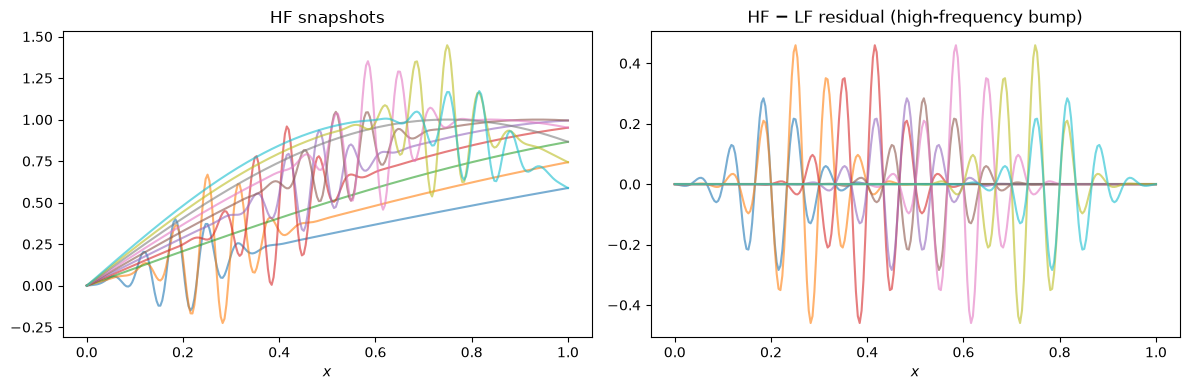

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import time
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import randomized_svd

from utils.sdn import ShallowDecoderNetwork, MyDataset, fit
from utils.mf_sdn import CorrectionDataset, ResidualSDNetwork, fit_res
from utils.mf_baselines import (
    LinearMFCorrector,
    PODGPRResidualCorrector,
    CoKrigingMFCorrector,
    evaluate_mf_methods,
)

device = 'cuda' if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu')
print('device:', device)

x = np.linspace(0, 1, 256)
mu_example = np.linspace(0.2, 0.8, 10)


def u_LF(x, mu):
    return np.sin(mu * np.pi * x)


def u_HF(x, mu):
    bump = 0.5 * np.sin(6 * np.pi * mu) * np.sin(30 * np.pi * x) * np.exp(-120 * (x - mu) ** 2)
    return u_LF(x, mu) + bump


U_HF = np.stack([u_HF(x, mu) for mu in mu_example])
U_LF = np.stack([u_LF(x, mu) for mu in mu_example])

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
axs[0].plot(x, U_HF.T, alpha=0.6)
axs[0].set_title('HF snapshots')
axs[0].set_xlabel('$x$')
axs[1].plot(x, (U_HF - U_LF).T, alpha=0.6)
axs[1].set_title('HF $-$ LF residual (high-frequency bump)')
axs[1].set_xlabel('$x$')
plt.tight_layout()
plt.show()


## LF surrogate (SDN from sparse sensors + $\mu$)

In [2]:
np.random.seed(60)
lf_params = np.linspace(mu_example[0], mu_example[-1], 200).reshape(-1, 1)
lf_snaps = np.stack([u_LF(x, mu[0]) for mu in lf_params]).T

n_sensors = 3
idx_sens_locs = np.random.choice(np.arange(len(x)), size=n_sensors, replace=False)

train_idx, test_idx, _, _ = train_test_split(np.arange(len(lf_params)), lf_params, test_size=0.1, random_state=42)
valid_idx = test_idx[::2]
test_idx = test_idx[1::2]

rank = 3
modes, sing_vals, _ = randomized_svd(lf_snaps[:, train_idx], n_components=rank, n_iter='auto')

def lf_inputs(idxs):
    return np.concatenate([lf_snaps[idx_sens_locs][:, idxs], lf_params[idxs].T], axis=0)

lf_input_scaler = MinMaxScaler().fit(lf_inputs(train_idx).T)

def scaled_lf_inputs(idxs):
    return lf_input_scaler.transform(lf_inputs(idxs).T).T

lf_sdn = ShallowDecoderNetwork(
    in_dim=scaled_lf_inputs(train_idx).shape[0],
    out_dim=rank,
    dropout=0.1,
    decoder_sizes=[350, 400],
    pod_modes=torch.tensor(modes, dtype=torch.float32).to(device),
).to(device)

fit(
    lf_sdn,
    MyDataset(torch.tensor(scaled_lf_inputs(train_idx).T, dtype=torch.float32).to(device), torch.tensor(lf_snaps[:, train_idx].T, dtype=torch.float32).to(device)),
    MyDataset(torch.tensor(scaled_lf_inputs(valid_idx).T, dtype=torch.float32).to(device), torch.tensor(lf_snaps[:, valid_idx].T, dtype=torch.float32).to(device)),
    batch_size=32,
    epochs=600,
    patience=30,
    verbose=True,
)
lf_sdn.freeze()
lf_modes = modes
lf_idx_sens_locs = idx_sens_locs


Training done: Training MRE = 0.50% 	 Validation MRE = 0.37%      


## MF dataset and residual SDN

HF train/valid/test: 9 3 18
Residual SDN training: 1.98 ss = 2.1883e-04 Validation Loss 2.9740e-03


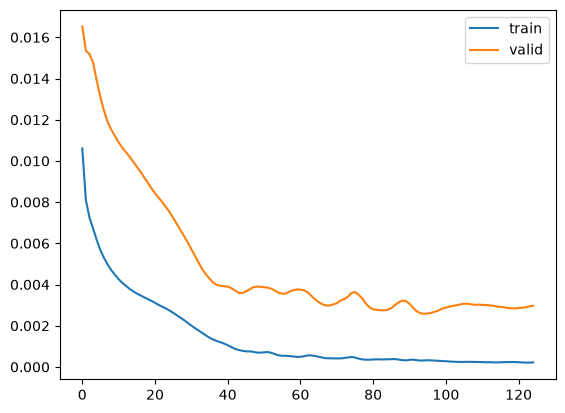

In [3]:
np.random.seed(42)
hf_params = np.linspace(mu_example[0] + 0.05, mu_example[-1], 50).reshape(-1, 1)
hf_snaps = np.stack([u_HF(x, mu[0]) for mu in hf_params]).T
lf_snaps_comparison = np.stack([u_LF(x, mu[0]) for mu in hf_params]).T

hf_idx_params_lhs = np.random.choice(np.arange(len(hf_params)), size=30, replace=False)
hf_params_lhs = hf_params[hf_idx_params_lhs]
hf_snaps_lhs = hf_snaps[:, hf_idx_params_lhs]
lf_snaps_lhs = lf_snaps_comparison[:, hf_idx_params_lhs]

train_indices, test_indices = train_test_split(np.arange(len(hf_params_lhs)), test_size=0.6, random_state=42)
train_indices, valid_indices = train_test_split(train_indices, test_size=0.2, random_state=42)
print('HF train/valid/test:', len(train_indices), len(valid_indices), len(test_indices))

_input = np.concatenate([lf_snaps_lhs[lf_idx_sens_locs], hf_params_lhs.T], axis=0)
_input = lf_input_scaler.transform(_input.T).T
_input = torch.tensor(_input, dtype=torch.float32).to(device).T

lf_sdn_red_coeff = lf_sdn.forward_pod(_input).cpu().detach().numpy()
train_input = lf_sdn_red_coeff[train_indices]
valid_input = lf_sdn_red_coeff[valid_indices]
test_input = lf_sdn_red_coeff[test_indices]

hf_input_scaler = MinMaxScaler().fit(train_input)
train_input = hf_input_scaler.transform(train_input)
valid_input = hf_input_scaler.transform(valid_input)
test_input = hf_input_scaler.transform(test_input)

train_delta_dataset = CorrectionDataset(
    torch.tensor(train_input, dtype=torch.float32).to(device),
    lf_sdn(_input)[train_indices].detach().clone(),
    torch.tensor(hf_snaps_lhs[:, train_indices].T, dtype=torch.float32).to(device),
)
valid_delta_dataset = CorrectionDataset(
    torch.tensor(valid_input, dtype=torch.float32).to(device),
    lf_sdn(_input)[valid_indices].detach().clone(),
    torch.tensor(hf_snaps_lhs[:, valid_indices].T, dtype=torch.float32).to(device),
)
test_delta_dataset = CorrectionDataset(
    torch.tensor(test_input, dtype=torch.float32).to(device),
    lf_sdn(_input)[test_indices].detach().clone(),
    torch.tensor(hf_snaps_lhs[:, test_indices].T, dtype=torch.float32).to(device),
)

in_dim = train_input.shape[1]
out_dim = hf_snaps_lhs.shape[0]
residual_sdn = ResidualSDNetwork(in_dim=in_dim, out_dim=out_dim, dropout=0.1, decoder_sizes=[350, 400]).to(device)

start = time.perf_counter()
train_res_errors, valid_res_errors = fit_res(
    model=residual_sdn,
    train_dataset=train_delta_dataset,
    valid_dataset=valid_delta_dataset,
    batch_size=32,
    epochs=600,
    patience=30,
    optim=torch.optim.Adam,
    criterion=nn.MSELoss(),
    lr=0.001,
    verbose=True,
)
residual_sdn_train_time = time.perf_counter() - start
print(f'Residual SDN training: {residual_sdn_train_time:.2f} s')

plt.plot(train_res_errors, label='train')
plt.plot(valid_res_errors, label='valid')
plt.legend()
plt.show()


### Tier B baselines
GP-residual uses the **same POD rank** as the LF SDN (`rank=3`). The oscillatory residual needs more modes; rank truncation is the failure mode we highlight.


In [4]:
mf_pod_rank = train_input.shape[1]
v_lf_train = train_delta_dataset.v_LF
u_lf_train = train_delta_dataset.u_LF
u_hf_train = train_delta_dataset.u_HF
mu_train = hf_params_lhs[train_indices]

start = time.perf_counter()
linear_mf = LinearMFCorrector(alpha=1e-6).fit(v_lf_train, u_lf_train, u_hf_train)
linear_fit_s = time.perf_counter() - start

start = time.perf_counter()
gp_residual = PODGPRResidualCorrector(rank=mf_pod_rank, alpha=1e-4).fit(v_lf_train, u_lf_train, u_hf_train)
gp_fit_s = time.perf_counter() - start

start = time.perf_counter()
cokriging_mf = CoKrigingMFCorrector(rank=mf_pod_rank, alpha=1e-4).fit(mu_train, u_lf_train, u_hf_train)
cokrig_fit_s = time.perf_counter() - start

pred_sdn_mf = (residual_sdn(test_delta_dataset.v_LF) + test_delta_dataset.u_LF).cpu().detach().numpy().T
pred_linear_mf = linear_mf.predict(test_delta_dataset.v_LF, test_delta_dataset.u_LF).T
pred_gp_mf = gp_residual.predict(test_delta_dataset.v_LF, test_delta_dataset.u_LF).T
pred_ck_mf = cokriging_mf.predict(hf_params_lhs[test_indices], test_delta_dataset.u_LF).T
test_hf_fom = test_delta_dataset.u_HF.cpu().numpy().T
test_lf_fom = test_delta_dataset.u_LF.cpu().numpy().T

mf_test_metrics = evaluate_mf_methods(
    test_hf_fom,
    {
        'Linear-MF': pred_linear_mf,
        'GP-residual': pred_gp_mf,
        'Co-kriging': pred_ck_mf,
        'SDN-MF': pred_sdn_mf,
    },
    reference_lf=test_lf_fom,
)

mf_summary = pd.DataFrame({
    'rel-L2 mean': [mf_test_metrics[m]['l2'] for m in ['LF', 'Linear-MF', 'GP-residual', 'Co-kriging', 'SDN-MF']],
    'rel-L2 std': [np.std(mf_test_metrics[m]['l2_per_sample']) for m in ['LF', 'Linear-MF', 'GP-residual', 'Co-kriging', 'SDN-MF']],
    'rel-max mean': [mf_test_metrics[m]['max'] for m in ['LF', 'Linear-MF', 'GP-residual', 'Co-kriging', 'SDN-MF']],
}, index=['LF', 'Linear-MF', 'GP-residual', 'Co-kriging', 'SDN-MF'])
display(mf_summary)

mf_costs = pd.DataFrame(
    {'fit [s]': [linear_fit_s, gp_fit_s, cokrig_fit_s, residual_sdn_train_time]},
    index=['Linear-MF', 'GP-residual', 'Co-kriging', 'SDN-MF'],
)
display(mf_costs)


/Users/rivas/Github/SDN4Neutronics/.venv/lib/python3.13/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-08. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/Users/rivas/Github/SDN4Neutronics/.venv/lib/python3.13/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/Users/rivas/Github/SDN4Neutronics/.venv/lib/python3.13/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


,rel-L2 mean,rel-L2 std,rel-max mean
LF,0.110769,0.047133,0.281272
Linear-MF,0.084481,0.035095,0.194836
GP-residual,0.076687,0.040140,0.177718
Co-kriging,0.086367,0.040958,0.187042
SDN-MF,0.065932,0.032696,0.152289


,fit [s]
Linear-MF,0.002108
GP-residual,0.018784
Co-kriging,0.014537
SDN-MF,1.975866


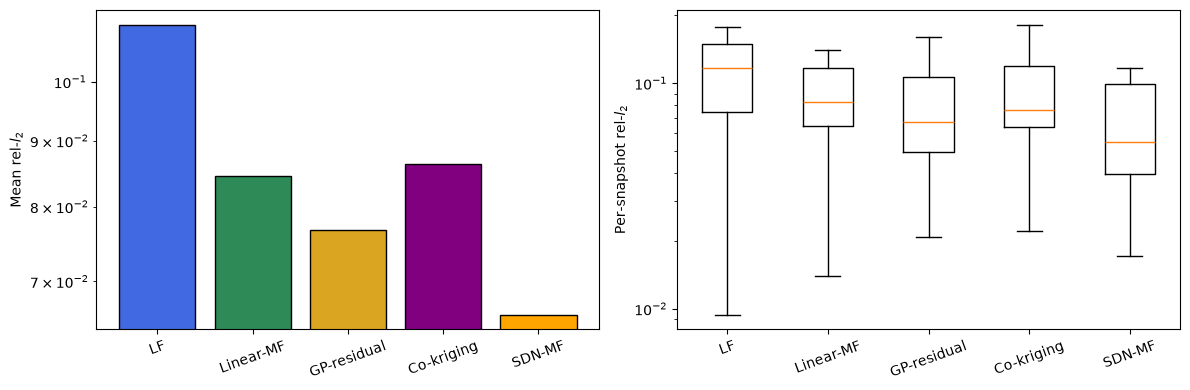

In [5]:
methods = ['LF', 'Linear-MF', 'GP-residual', 'Co-kriging', 'SDN-MF']
colors = ['royalblue', 'seagreen', 'goldenrod', 'purple', 'orange']

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
axs[0].bar(methods, [mf_test_metrics[m]['l2'] for m in methods], color=colors, edgecolor='black')
axs[0].set_yscale('log')
axs[0].set_ylabel('Mean rel-$l_2$')
axs[0].tick_params(axis='x', rotation=20)

axs[1].boxplot([mf_test_metrics[m]['l2_per_sample'] for m in methods], tick_labels=methods)
axs[1].set_yscale('log')
axs[1].set_ylabel('Per-snapshot rel-$l_2$')
axs[1].tick_params(axis='x', rotation=20)
plt.tight_layout()
plt.show()


### Field plots
GP-residual tends to **oversmooth** the localized oscillatory correction; SDN-MF captures the bump near $x=\mu$.


<>:13: SyntaxWarning: invalid escape sequence '\m'
<>:13: SyntaxWarning: invalid escape sequence '\m'
/var/folders/wj/ljx542lx73z3721_ddn_zwtc0000gp/T/ipykernel_79161/3350373238.py:13: SyntaxWarning: invalid escape sequence '\m'
  ax.set_ylabel(f'$\mu={mu_val:.2f}$')


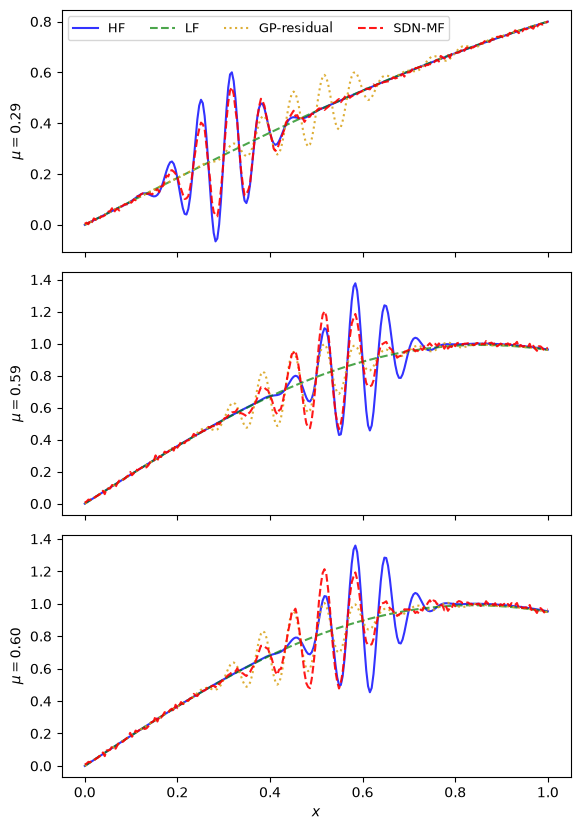

In [6]:
plot_idx = np.argsort(mf_test_metrics['GP-residual']['l2_per_sample'])[-3:][::-1]

fig, axs = plt.subplots(len(plot_idx), 1, figsize=(6, 2.8 * len(plot_idx)), sharex=True)
if len(plot_idx) == 1:
    axs = [axs]

for ax, jj in zip(axs, plot_idx):
    mu_val = hf_params_lhs[test_indices[jj], 0]
    ax.plot(x, test_hf_fom[:, jj], 'b', label='HF', alpha=0.8)
    ax.plot(x, test_lf_fom[:, jj], 'g--', label='LF', alpha=0.7)
    ax.plot(x, pred_gp_mf[:, jj], color='goldenrod', ls=':', label='GP-residual', alpha=0.9)
    ax.plot(x, pred_sdn_mf[:, jj], 'r--', label='SDN-MF', alpha=0.9)
    ax.set_ylabel(f'$\mu={mu_val:.2f}$')

axs[0].legend(ncol=4, fontsize=9)
axs[-1].set_xlabel('$x$')
plt.tight_layout()
plt.show()


**Takeaway:** On the smooth `ExampleMF1D` benchmark GP-residual is often best. Here the correction is high-frequency and localized; with a **rank-limited POD basis** GP-residual underperforms the direct field map learned by the residual SDN.
